In [1]:
import sys
print(sys.executable)


/home/cloud/anaconda3/bin/python


In [3]:
%pip install --user scikit-learn matplotlib seaborn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 139.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 116.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install --user --force-reinstall --no-cache-dir \
"numpy==1.26.4" \
"pandas==2.2.3" \
"scipy==1.14.1" \
"scikit-learn==1.5.2" \
"matplotlib==3.9.2" \
"seaborn==0.13.2" \
"joblib==1.4.2" \
"streamlit==1.39.0" \
"pyarrow==17.0.0"

INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 186.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 262.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 MB 295.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 338.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 332.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 276.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.9/39.9 MB 300.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.2/731.2 kB 421.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 292.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 339.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 324.3 

In [1]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn
import streamlit
import joblib

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Streamlit uploaded successfully")
print("All packages are ready.")


NumPy: 1.26.4
Pandas: 2.2.3
scikit-learn: 1.5.2
Streamlit uploaded successfully
All packages are ready.


In [3]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [5]:
from pathlib import Path
import pandas as pd

csv_files = list(Path(".").rglob("bank-additional-full.csv"))

if not csv_files:
    raise FileNotFoundError(
        "bank-additional-full.csv was not found."
        "Please confirm that it was uploaded in the BITS Lab file browser."
    )

csv_path = csv_files[0]
print("Using dataset file:", csv_path)

data = pd.read_csv(csv_path, sep=";")

print("Dataset shape:", data.shape)
print("Input Features:", data.shape[1] - 1)
print("\nTarget distribution:")
print(data["y"].value_counts())

Using dataset file: bank-additional-full.csv
Dataset shape: (41188, 21)
Input Features: 20

Target distribution:
y
no     36548
yes     4640
Name: count, dtype: int64


In [7]:
import pandas as pd

data = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset loaded successfully:", data.shape)
print(data["y"].value_counts())

Dataset loaded successfully: (41188, 21)
y
no     36548
yes     4640
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

# Use all input columns except "duration"; y is the target column.
X = data.drop(columns=["y", "duration"])
y = data["y"].map({"no": 0, "yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Save the held-out test data for the Streamlit application.
test_data = X_test.copy()
test_data["y"] = y_test
test_data.to_csv("test_data.csv", index=False)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("\nSaved test_data.csv successfully")
print("\nTraining target distribution:")
print(y_train.value_counts())

Training features: (32950, 19)
Test features: (8238, 19)

Saved test_data.csv successfully

Training target distribution:
y
0    29238
1     3712
Name: count, dtype: int64


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_columns = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numeric columns:", numeric_columns)
print("\nCategorical columns:", categorical_columns)

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_columns),
    ("categorical", categorical_preprocessor, categorical_columns)
])

print("\nPreprocessor created successfully.")

Numeric columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Preprocessor created successfully.


In [13]:
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

Path("models").mkdir(exist_ok=True)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),
    
    "KNN": KNeighborsClassifier(
        n_neighbors=15,
        weights="distance"
    ),
    
    "Naive Bayes": GaussianNB(),
    
    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=42
    )
}

print("Models ready:")
for model_name in models:
    print("-", model_name)

Models ready:
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- SVM


In [25]:
from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)
import pandas as pd
import joblib

Path("outputs").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)

results = []
saved_pipelines = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    # AUC uses probability scores when available; otherwise, SVM decision scores.
    if hasattr(pipeline, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_score = pipeline.decision_function(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

    filename = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipeline, f"models/{filename}")

    saved_pipelines[model_name] = pipeline
    print(f"{model_name} completed and saved as models/{filename}")

results_df = pd.DataFrame(results).sort_values(by="F1", ascending=False)
results_df.to_csv("outputs/metrics_comparison.csv", index=False)

print("\nAll models completed.")
display(results_df.round(4))

Training Logistic Regression...
Logistic Regression completed and saved as models/logistic_regression.joblib
Training Decision Tree...
Decision Tree completed and saved as models/decision_tree.joblib
Training KNN...
KNN completed and saved as models/knn.joblib
Training Naive Bayes...
Naive Bayes completed and saved as models/naive_bayes.joblib
Training SVM...
SVM completed and saved as models/svm.joblib

All models completed.


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
4,SVM,0.8577,0.7828,0.4140,0.6325,0.5004,0.4346
0,Logistic Regression,0.8350,0.8009,0.3679,0.6466,0.4689,0.4011
1,Decision Tree,0.8269,0.7804,0.3496,0.6239,0.4481,0.3760
3,Naive Bayes,0.8049,0.7755,0.3172,0.6347,0.4230,0.3490
2,KNN,0.8951,0.7555,0.5731,0.2705,0.3675,0.3451


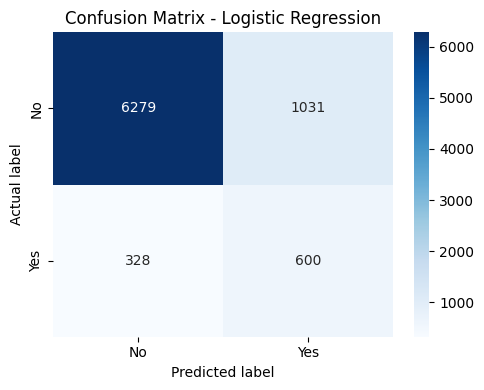


Classification report - Logistic Regression
              precision    recall  f1-score   support

          No       0.95      0.86      0.90      7310
         Yes       0.37      0.65      0.47       928

    accuracy                           0.84      8238
   macro avg       0.66      0.75      0.69      8238
weighted avg       0.88      0.84      0.85      8238



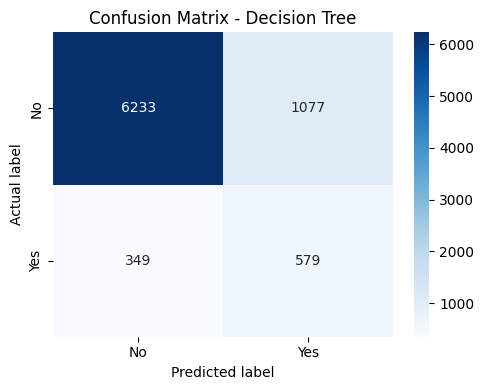


Classification report - Decision Tree
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7310
         Yes       0.35      0.62      0.45       928

    accuracy                           0.83      8238
   macro avg       0.65      0.74      0.67      8238
weighted avg       0.88      0.83      0.85      8238



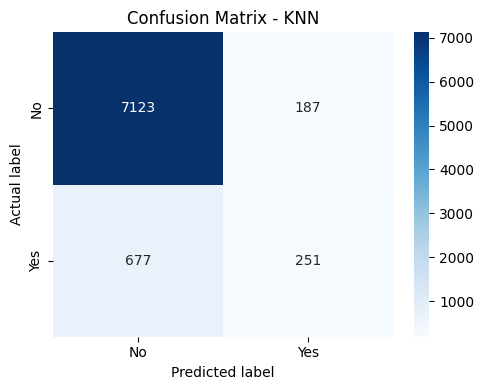


Classification report - KNN
              precision    recall  f1-score   support

          No       0.91      0.97      0.94      7310
         Yes       0.57      0.27      0.37       928

    accuracy                           0.90      8238
   macro avg       0.74      0.62      0.66      8238
weighted avg       0.87      0.90      0.88      8238



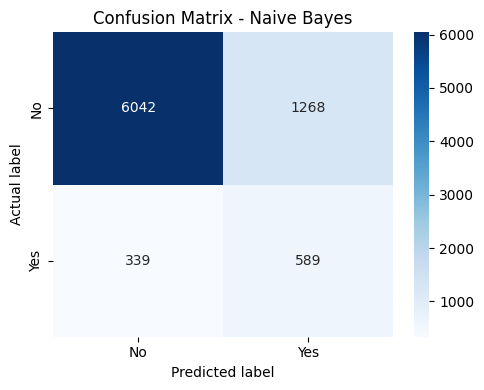


Classification report - Naive Bayes
              precision    recall  f1-score   support

          No       0.95      0.83      0.88      7310
         Yes       0.32      0.63      0.42       928

    accuracy                           0.80      8238
   macro avg       0.63      0.73      0.65      8238
weighted avg       0.88      0.80      0.83      8238



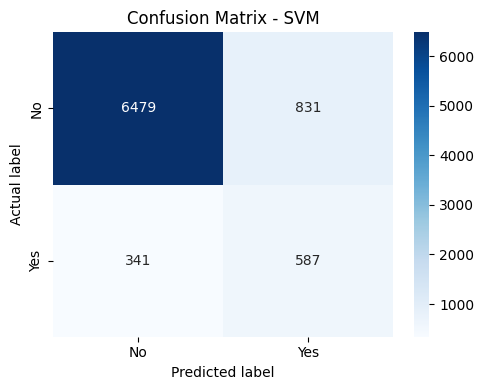


Classification report - SVM
              precision    recall  f1-score   support

          No       0.95      0.89      0.92      7310
         Yes       0.41      0.63      0.50       928

    accuracy                           0.86      8238
   macro avg       0.68      0.76      0.71      8238
weighted avg       0.89      0.86      0.87      8238



In [17]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

Path("outputs/confusion_matrices").mkdir(parents=True, exist_ok=True)

for model_name, pipeline in saved_pipelines.items():
    y_pred = pipeline.predict(X_test)
    matrix = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_") + "_confusion_matrix.png"
    plt.savefig(f"outputs/confusion_matrices/{filename}", dpi=150)
    plt.show()

    print(f"\nClassification report - {model_name}")
    print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

In [19]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib

Writing requirements.txt


In [21]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

st.set_page_config(page_title="Bank Marketing Classifier", page_icon="📊")

MODEL_FILES = {
    "Logistic Regression": "models/logistic_regression.joblib",
    "Decision Tree": "models/decision_tree.joblib",
    "KNN": "models/knn.joblib",
    "Naive Bayes": "models/naive_bayes.joblib",
    "SVM": "models/svm.joblib"
}

@st.cache_resource
def load_model(model_path):
    return joblib.load(model_path)

st.title("Bank Marketing Classification App")
st.write(
    "Upload a test CSV containing the 19 input features and the target column `y`. "
    "The selected saved model will evaluate the data without retraining."
)

selected_model_name = st.selectbox("Choose a model", list(MODEL_FILES.keys()))
uploaded_file = st.file_uploader("Upload test_data.csv", type=["csv"])

if uploaded_file is not None:
    test_data = pd.read_csv(uploaded_file)

    if "y" not in test_data.columns:
        st.error("The uploaded CSV must contain the target column named 'y'.")
    else:
        model = load_model(MODEL_FILES[selected_model_name])

        X_uploaded = test_data.drop(columns="y")
        y_actual = test_data["y"]

        expected_columns = list(model.feature_names_in_)
        missing_columns = set(expected_columns) - set(X_uploaded.columns)

        if missing_columns:
            st.error(f"Missing required columns: {sorted(missing_columns)}")
        else:
            X_uploaded = X_uploaded[expected_columns]
            y_pred = model.predict(X_uploaded)

            if hasattr(model, "predict_proba"):
                y_score = model.predict_proba(X_uploaded)[:, 1]
            else:
                y_score = model.decision_function(X_uploaded)

            metrics = pd.DataFrame([{
                "Accuracy": accuracy_score(y_actual, y_pred),
                "AUC": roc_auc_score(y_actual, y_score),
                "Precision": precision_score(y_actual, y_pred, zero_division=0),
                "Recall": recall_score(y_actual, y_pred, zero_division=0),
                "F1-score": f1_score(y_actual, y_pred, zero_division=0),
                "MCC": matthews_corrcoef(y_actual, y_pred)
            }])

            st.subheader(f"Evaluation: {selected_model_name}")
            st.dataframe(metrics.round(4), use_container_width=True)

            matrix = confusion_matrix(y_actual, y_pred)

            fig, ax = plt.subplots(figsize=(5, 4))
            sns.heatmap(
                matrix,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=["No", "Yes"],
                yticklabels=["No", "Yes"],
                ax=ax
            )
            ax.set_xlabel("Predicted label")
            ax.set_ylabel("Actual label")
            ax.set_title(f"Confusion Matrix - {selected_model_name}")
            st.pyplot(fig)

            report = classification_report(
                y_actual,
                y_pred,
                target_names=["No", "Yes"],
                output_dict=True
            )

            st.subheader("Classification Report")
            st.dataframe(pd.DataFrame(report).transpose().round(4))

Writing app.py


In [23]:
%%writefile README.md
# Bank Marketing Classification

## Problem Statement
Predict whether a bank client will subscribe to a term deposit based on customer, campaign, and economic information.

## Dataset Description
- Source: UCI Machine Learning Repository - Bank Marketing
- Instances: 41,188
- Original input features: 20
- Target: `y` (`no` = 0, `yes` = 1)
- Split: 80% training and 20% testing
- Feature decision: `duration` was excluded because it is known after the marketing call and could cause data leakage.

## Models Used
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

## Model Comparison

| Model | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8350 | 0.8009 | 0.3679 | 0.6466 | 0.4689 | 0.4011 |
| Decision Tree | 0.8265 | 0.7777 | 0.3488 | 0.6228 | 0.4472 | 0.3748 |
| KNN | 0.8949 | 0.7553 | 0.5708 | 0.2694 | 0.3660 | 0.3434 |
| Naive Bayes | 0.8049 | 0.7755 | 0.3172 | 0.6347 | 0.4230 | 0.3490 |
| SVM | 0.8577 | 0.7829 | 0.4140 | 0.6325 | 0.5004 | 0.4346 |

## Observations
-Logistic Regression: Highest AUC and recall, but lower precision means more false-positive "Yes" predictions.
-Decision Tree: moderate performance across metrics; lower F1 and MCC than SVM.
-KNN: Highest accuracy and precision, but very low recall, so it misses many actual "Yes" cases
-Naive Bayes: Lower F1 and MCC than the stronger models.
-SVM: Best F1 and MCC; strongest overall balance for the minority"Yes" class.

## Overall Winner
SVM was selected as the best overall model because it achieved the highest F1-score and MCC, which are more informative than accuracy for this imbalanced dataset.

## How to Run Locally
```bash
pip install -r requirements.txt
streamlit run app.py

Writing README.md
